<a href="https://colab.research.google.com/github/thvsbg/PyTorch/blob/main/Wine_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [66]:
import torch
import matplotlib.pyplot as plt
import pandas as pd


In [67]:
from sklearn.datasets import load_wine
data=load_wine()
features=data.data
val=data.target
print(features[:5])
print(val[:5])

[[1.423e+01 1.710e+00 2.430e+00 1.560e+01 1.270e+02 2.800e+00 3.060e+00
  2.800e-01 2.290e+00 5.640e+00 1.040e+00 3.920e+00 1.065e+03]
 [1.320e+01 1.780e+00 2.140e+00 1.120e+01 1.000e+02 2.650e+00 2.760e+00
  2.600e-01 1.280e+00 4.380e+00 1.050e+00 3.400e+00 1.050e+03]
 [1.316e+01 2.360e+00 2.670e+00 1.860e+01 1.010e+02 2.800e+00 3.240e+00
  3.000e-01 2.810e+00 5.680e+00 1.030e+00 3.170e+00 1.185e+03]
 [1.437e+01 1.950e+00 2.500e+00 1.680e+01 1.130e+02 3.850e+00 3.490e+00
  2.400e-01 2.180e+00 7.800e+00 8.600e-01 3.450e+00 1.480e+03]
 [1.324e+01 2.590e+00 2.870e+00 2.100e+01 1.180e+02 2.800e+00 2.690e+00
  3.900e-01 1.820e+00 4.320e+00 1.040e+00 2.930e+00 7.350e+02]]
[0 0 0 0 0]


In [ ]:
##finding the number of features for each wine
print(len(features[0]))

13


In [3]:
import collections
val_unique_counts=collections.Counter(val)
print(val_unique_counts)

Counter({np.int64(1): 71, np.int64(0): 59, np.int64(2): 48})


In [4]:
##finding the range of each feature
min_max=pd.DataFrame(columns=["min","max"],index=data.feature_names)
for i in range(len(data.feature_names)):
  min_max.loc[data.feature_names[i]]=[min(features[:,i]),max(features[:,i])]
print(min_max)

                                min     max
alcohol                       11.03   14.83
malic_acid                     0.74     5.8
ash                            1.36    3.23
alcalinity_of_ash              10.6    30.0
magnesium                      70.0   162.0
total_phenols                  0.98    3.88
flavanoids                     0.34    5.08
nonflavanoid_phenols           0.13    0.66
proanthocyanins                0.41    3.58
color_intensity                1.28    13.0
hue                            0.48    1.71
od280/od315_of_diluted_wines   1.27     4.0
proline                       278.0  1680.0


In [ ]:
## feature scaling


In [5]:
cols=data.feature_names
print(cols)


['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


In [23]:
wine_1=[1 if val[i]==0 else 0 for i in range(len(val))]
wine_2=[1 if val[i]==1 else 0 for i in range(len(val))]
wine_3=[1 if val[i]==2 else 0 for i in range(len(val))]
print(wine_1[:5])
print(wine_2[:5])
print(wine_3[:5])

[1, 1, 1, 1, 1]
[0, 0, 0, 0, 0]
[0, 0, 0, 0, 0]


In [24]:
df=pd.DataFrame(features,columns=data.feature_names)
df["wine_1"]=wine_1
df["wine_2"]=wine_2
df["wine_3"]=wine_3
print(df[:5])

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  wine_1  wine_2  wine

In [ ]:
df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_1,wine_2,wine_3
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.331461,0.398876,0.269663
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.472066,0.491049,0.445037
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000,0.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000,0.000000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,0.000000,0.000000,0.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,1.000000,1.000000,1.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,1.000000,1.000000,1.000000


In [ ]:
##mean is almost half of the max value


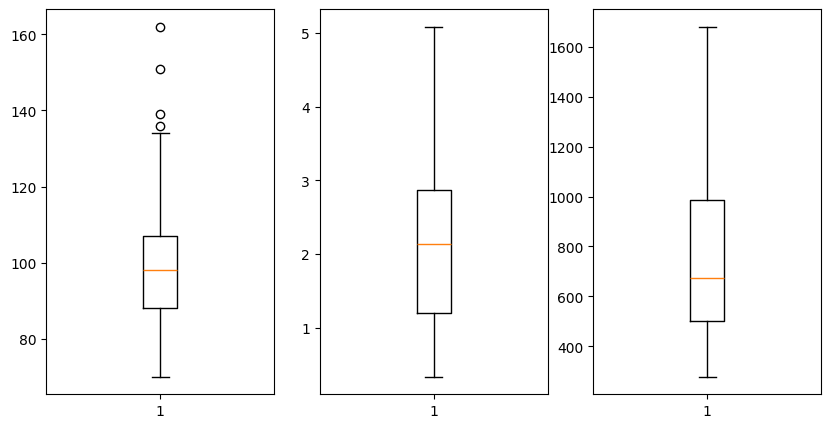

In [ ]:
figure,(ax1,ax2,ax3)=plt.subplots(1,3,figsize=(10,5))
ax1.boxplot(df.magnesium)
ax2.boxplot(df.flavanoids)
ax3.boxplot(df.proline)
plt.show()

In [ ]:
##scaling
## mean of proline almost half of the max. value, StandardScaler seems like a good choice

In [68]:
##scaling
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
features=scaler.fit_transform(features)
print(features[:5])

[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


Standard scaler
-> It scales a value to how many standard deviations it is away from the mean.
Eg:In case of Proline
A value of 431 becomes approximately:
  431-746/315=-1

431 is 1 standard devisation in the negative direction from mean
==> 431-746= -1 *(315) = -1*(std)


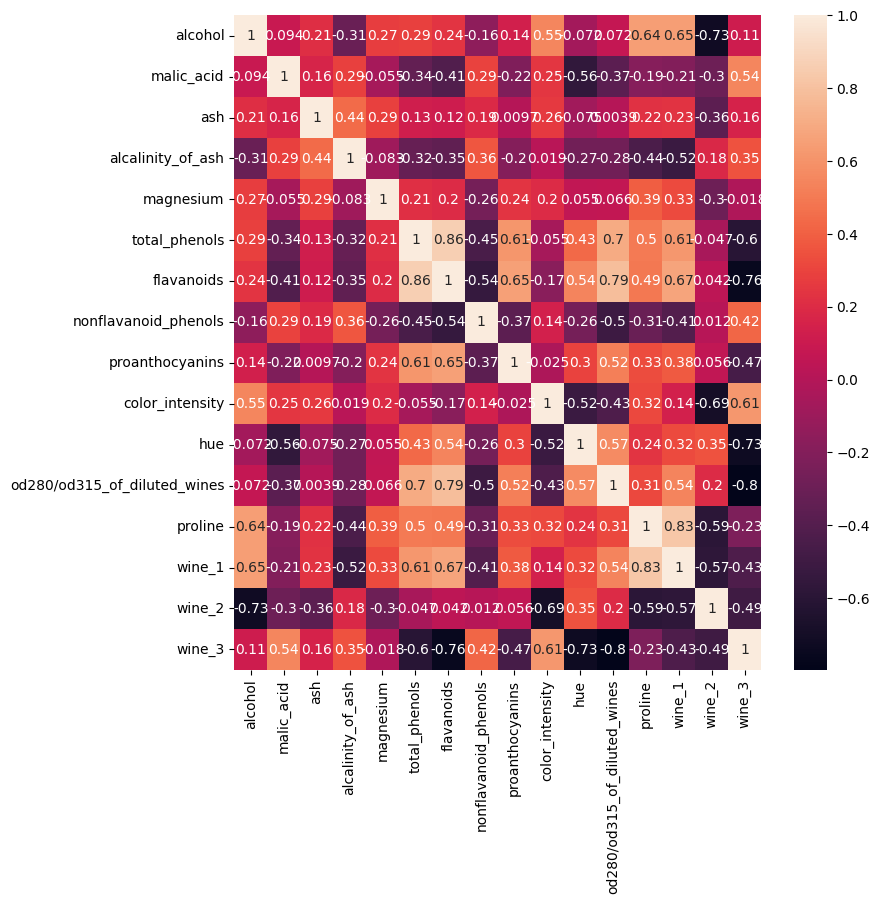

In [ ]:
##visuzlization of corelation between different features to the classified value using heatmap
import seaborn as sns
fig=plt.figure(figsize=(8.5,8.5))
correlation=df.corr(numeric_only=True)
sns.heatmap(correlation,annot=True)
plt.show()


1. Wine_1 is strongly correlated to total_phenols and flavanoids.Let's further analyze using a scatter plot


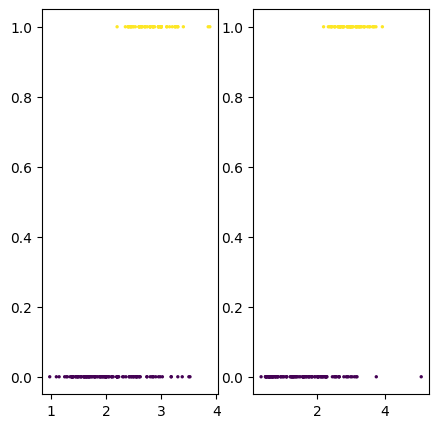

In [ ]:
##exploring relation between wine_1 and total_phenols, flavanoids
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(5,5))
ax1.scatter(df["total_phenols"],df["wine_1"],c=df["wine_1"],s=2)

ax2.scatter(df["flavanoids"],df["wine_1"],c=df["wine_1"],s=2)

plt.show()

##Building a nn

In [69]:
from torch import nn


In [70]:
##dataprep
features=torch.from_numpy(features).type(torch.float)
val=torch.from_numpy(val).type(torch.LongTensor)
print(features[:5])
print(val[:5])

tensor([[ 1.5186, -0.5622,  0.2321, -1.1696,  1.9139,  0.8090,  1.0348, -0.6596,
          1.2249,  0.2517,  0.3622,  1.8479,  1.0130],
        [ 0.2463, -0.4994, -0.8280, -2.4908,  0.0181,  0.5686,  0.7336, -0.8207,
         -0.5447, -0.2933,  0.4061,  1.1134,  0.9652],
        [ 0.1969,  0.0212,  1.1093, -0.2687,  0.0884,  0.8090,  1.2155, -0.4984,
          2.1360,  0.2690,  0.3183,  0.7886,  1.3951],
        [ 1.6915, -0.3468,  0.4879, -0.8093,  0.9309,  2.4914,  1.4665, -0.9819,
          1.0322,  1.1861, -0.4275,  1.1841,  2.3346],
        [ 0.2957,  0.2277,  1.8404,  0.4519,  1.2820,  0.8090,  0.6634,  0.2268,
          0.4014, -0.3193,  0.3622,  0.4496, -0.0379]])
tensor([0, 0, 0, 0, 0])


In [71]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(features,val,test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=torch.tensor(scaler.fit_transform(X_train))
X_test=scaler.transform(X_test)

In [ ]:
print(X_train.dtype)

torch.float32


In [72]:
class WineClassification(nn.Module):
  def __init__(self,input_features,hidden_units,output_features):
    super().__init__()
    self.nn_stack=nn.Sequential(
        nn.Linear(input_features,hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units,hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units,hidden_units),
        nn.ReLU(),
        nn.Linear(hidden_units,output_features)
    )

  def forward(self,x):
    return self.nn_stack(x)




In [73]:
model_0=WineClassification(13,5,3)
loss_fn=nn.CrossEntropyLoss()
opt=torch.optim.SGD(params=model_0.parameters(),lr=0.001)

In [74]:
##train loop
RANDOM_SEED=42
torch.random.manual_seed(RANDOM_SEED)
epochs=1000
train_loss=[]
for epoch in range(epochs):
  model_0.train()
  pred_logits=model_0(X_train).squeeze()
  pred_prob=torch.softmax(pred_logits,dim=1)
  pred_labels=torch.argmax(pred_prob,dim=1)

  loss=loss_fn(pred_logits,y_train)
  train_loss.append(loss.detach())


  opt.zero_grad

  loss.backward()

  opt.step()

  model_0.eval()
  with torch.inference_mode():
    test_pred_logits=model_0(X_test)
    test_pred_prob=torch.softmax(test_pred_logits,dim=1)
    test_pred_labels=torch.argmax(test_pred_prob,dim=1)

    test_loss=loss_fn(test_pred_logits,y_test)

  if epoch%100==0:
    print(f'loss at epoch no.{epoch} is: {loss}')

loss at epoch no.0 is: 1.095966100692749
loss at epoch no.100 is: 1.0876671075820923
loss at epoch no.200 is: 1.0659140348434448
loss at epoch no.300 is: 0.8364511132240295
loss at epoch no.400 is: 0.401711642742157
loss at epoch no.500 is: 0.14545482397079468
loss at epoch no.600 is: 0.025600723922252655
loss at epoch no.700 is: 0.0022806450724601746
loss at epoch no.800 is: 0.0023822858929634094
loss at epoch no.900 is: 0.0001542801910545677


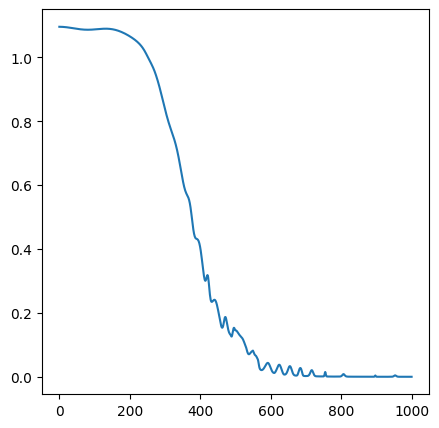

In [75]:
fig=plt.figure(figsize=(5,5))
plt.plot(train_loss)
plt.show()

In [81]:
##scaling of test
X_test=scaler.transform(X_test)
with torch.inference_mode():
  test_pred_logits=model_0(torch.tensor(X_test).type(torch.float))
  test_pred_prob=torch.softmax(test_pred_logits,dim=1)
  test_pred_labels=torch.argmax(test_pred_prob,dim=1)

##accuracy of test preds
test_df=pd.DataFrame({"y_test":y_test,"test_pred_labels":test_pred_labels})
print(test_df)

    y_test  test_pred_labels
0        0                 1
1        0                 1
2        2                 2
3        0                 1
4        1                 1
5        0                 1
6        1                 1
7        2                 2
8        1                 1
9        2                 1
10       0                 1
11       2                 1
12       0                 1
13       1                 2
14       0                 1
15       1                 1
16       1                 2
17       1                 0
18       0                 1
19       1                 2
20       0                 1
21       1                 1
22       1                 2
23       2                 1
24       2                 2
25       2                 2
26       1                 1
27       1                 1
28       1                 2
29       0                 1
30       0                 1
31       1                 1
32       2                 2
33       0    

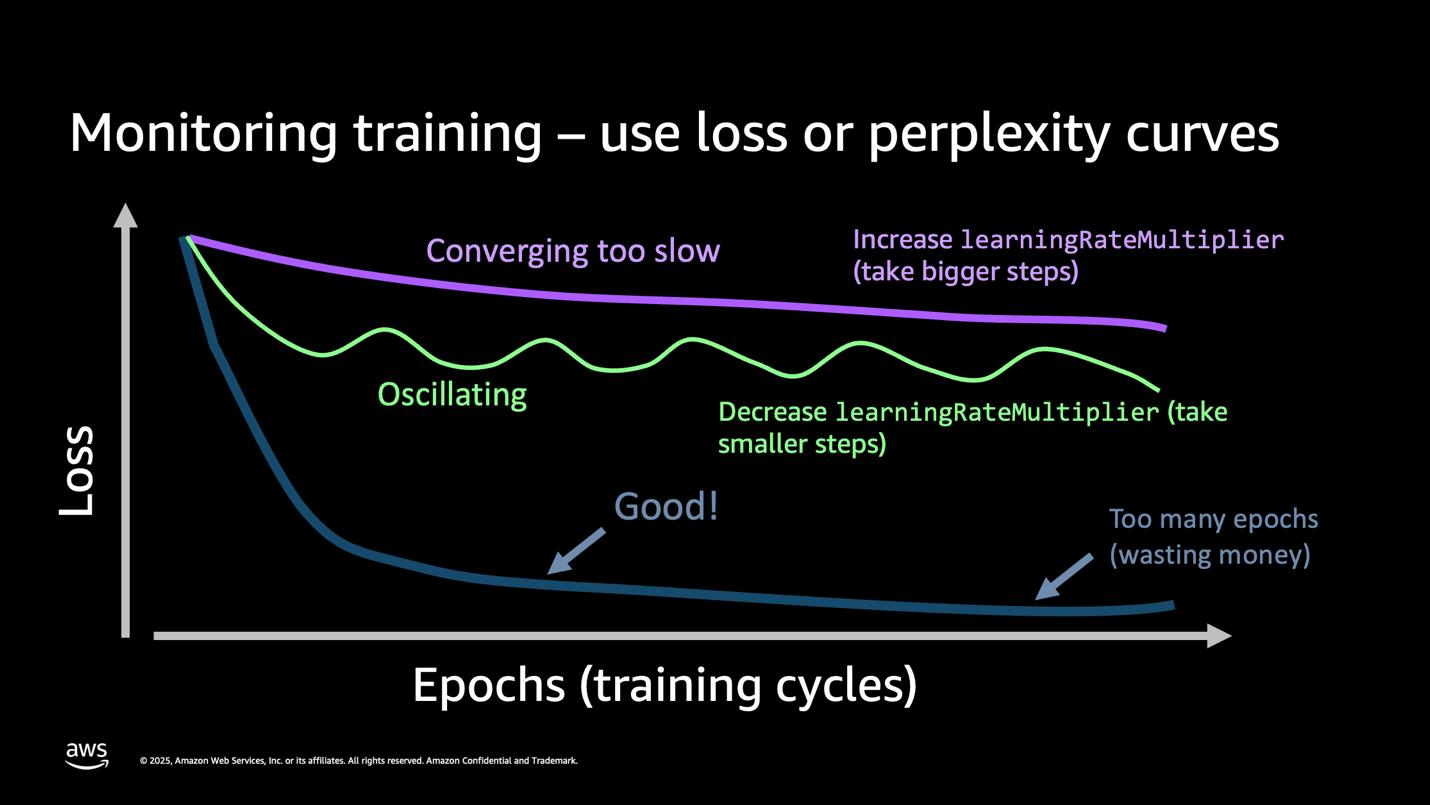